# Task 11 — Independent task: UCI Mice Protein Expression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

DATA = Path('/home/uliana/Desktop/ML_bioinforrmatics/KSE_ML_for_bioinformatics/practicals/week1')
mice = pd.read_csv(DATA / 'Data_Cortex_Nuclear.csv')
mice['mouse_id'] = mice['MouseID'].astype(str).str.rsplit('_', n=1).str[0]

print('rows, columns:', mice.shape)
print('columns:')
print(list(mice.columns[:10]) + ['...'] + list(mice.columns[-5:]))
mice.head()


rows, columns: (1080, 83)
columns:
['MouseID', 'DYRK1A_N', 'ITSN1_N', 'BDNF_N', 'NR1_N', 'NR2A_N', 'pAKT_N', 'pBRAF_N', 'pCAMKII_N', 'pCREB_N', '...', 'Genotype', 'Treatment', 'Behavior', 'class', 'mouse_id']


,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,...,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class,mouse_id
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,...,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m,309
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,...,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m,309
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,...,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m,309
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,...,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m,309
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,...,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m,309


## A. Data presentation

In [2]:
protein_cols = [c for c in mice.columns if c not in ['MouseID', 'mouse_id', 'Genotype', 'Treatment', 'Behavior', 'class']]
print('Number of protein variables:', len(protein_cols))
print('Protein columns sample:', protein_cols[:10])
print('Non-protein metadata columns:', [c for c in mice.columns if c not in protein_cols])

print('Example rows per mouse:')
print(mice.groupby('mouse_id').size().value_counts().sort_index().to_string())
print('Unique mice:', mice['mouse_id'].nunique())
print('Rows per mouse summary:')
print(mice.groupby('mouse_id').size().describe().to_string())


Number of protein variables: 77
Protein columns sample: ['DYRK1A_N', 'ITSN1_N', 'BDNF_N', 'NR1_N', 'NR2A_N', 'pAKT_N', 'pBRAF_N', 'pCAMKII_N', 'pCREB_N', 'pELK_N']
Non-protein metadata columns: ['MouseID', 'Genotype', 'Treatment', 'Behavior', 'class', 'mouse_id']
Example rows per mouse:
15    72
Unique mice: 72
Rows per mouse summary:
count    72.0
mean     15.0
std       0.0
min      15.0
25%      15.0
50%      15.0
75%      15.0
max      15.0


Counts for Genotype: {'Control': 570, 'Ts65Dn': 510}
Counts for Treatment: {'Memantine': 570, 'Saline': 510}
Counts for Behavior: {'S/C': 555, 'C/S': 525}
Counts for class: {'c-CS-m': 150, 'c-SC-m': 150, 'c-CS-s': 135, 'c-SC-s': 135, 't-CS-m': 135, 't-SC-m': 135, 't-SC-s': 135, 't-CS-s': 105}


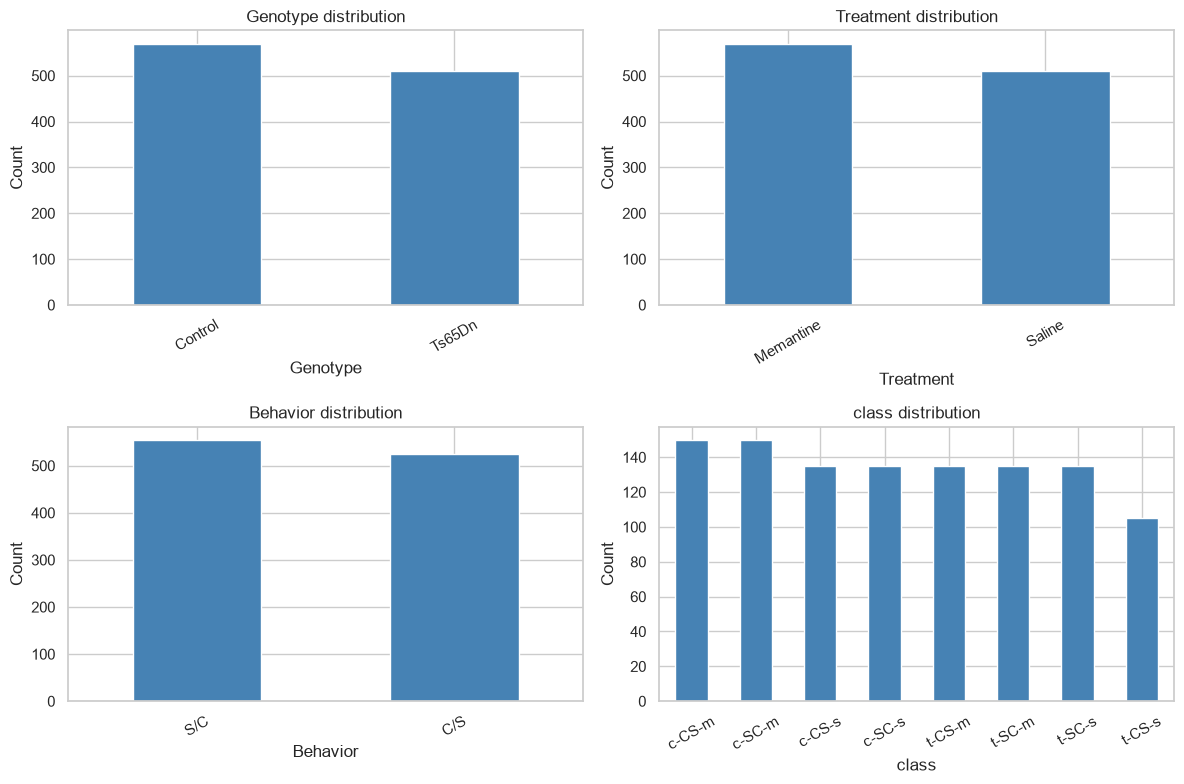

In [4]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ['Genotype', 'Treatment', 'Behavior', 'class']):
    counts = mice[col].value_counts()
    counts.plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(f'{col} distribution')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=30)
    print(f"Counts for {col}: {counts.to_dict()}")
plt.tight_layout()
plt.show()


## B. EDA and tidy-data assessment

/tmp/ipykernel_26729/664682569.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=mice, x='Genotype', y=protein, palette='Set2')
/tmp/ipykernel_26729/664682569.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=mice, x='Genotype', y=protein, palette='Set2')
/tmp/ipykernel_26729/664682569.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=mice, x='Genotype', y=protein, palette='Set2')
/tmp/ipykernel_26729/664682569.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. 

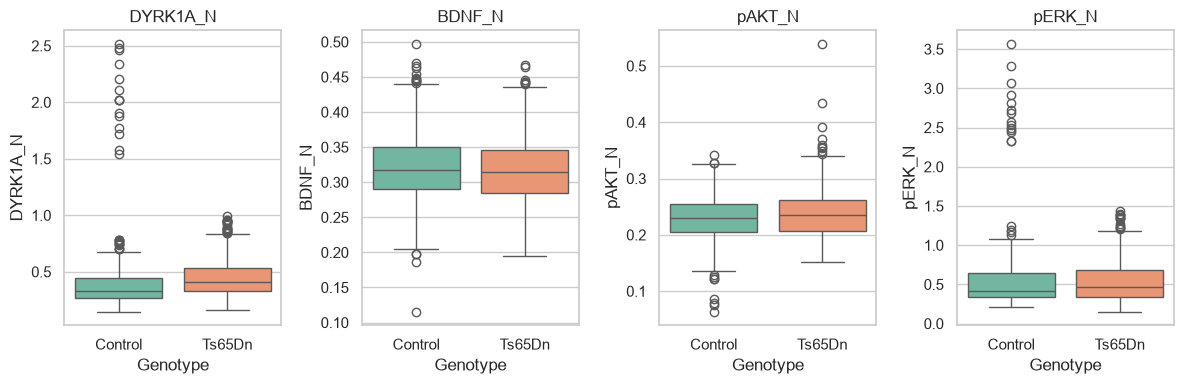

In [5]:
selected = ['DYRK1A_N', 'BDNF_N', 'pAKT_N', 'pERK_N']
mice_long = mice.melt(id_vars=['Genotype', 'Treatment', 'Behavior', 'class'], value_vars=selected, var_name='Protein', value_name='Expression')

plt.figure(figsize=(12, 4))
for i, protein in enumerate(selected, start=1):
    plt.subplot(1, len(selected), i)
    sns.boxplot(data=mice, x='Genotype', y=protein, palette='Set2')
    plt.title(protein)
plt.tight_layout()
plt.show()


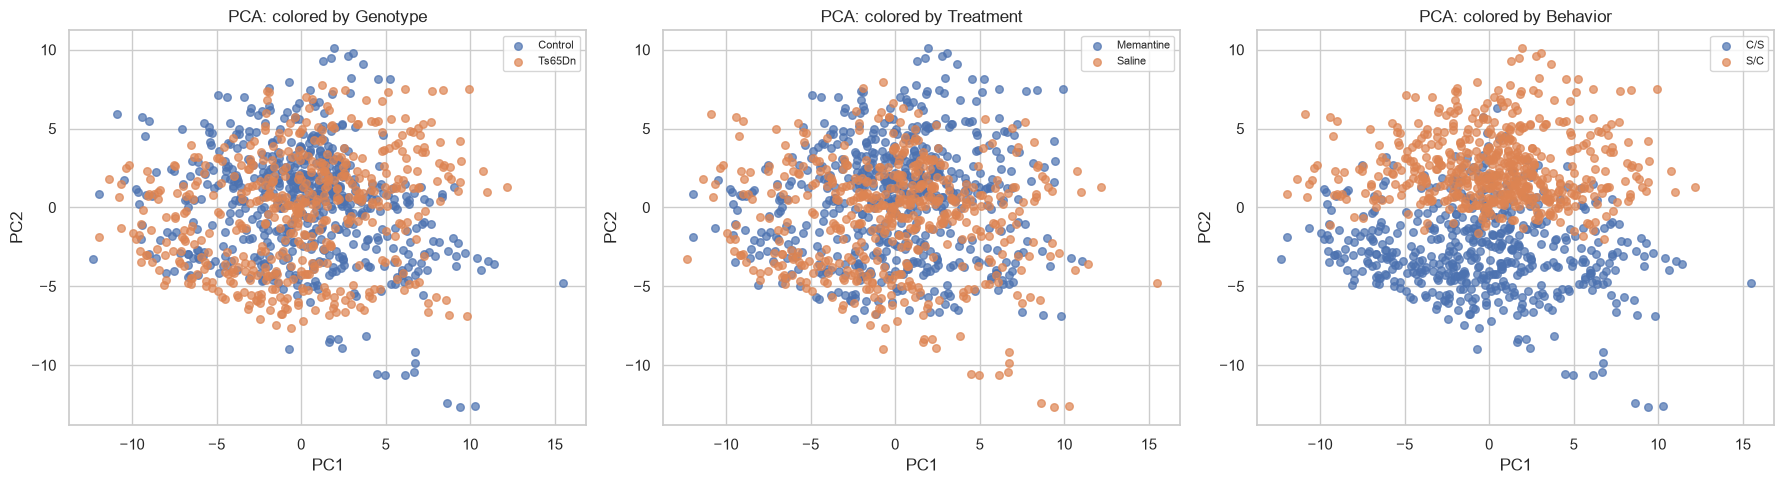

Explained variance by first two PCs: [0.253 0.169]


In [6]:
X_proj = mice[protein_cols].copy()
imputer = SimpleImputer(strategy='median')
X_proj_imputed = pd.DataFrame(imputer.fit_transform(X_proj), columns=X_proj.columns, index=X_proj.index)
X_scaled = StandardScaler().fit_transform(X_proj_imputed)
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({
    'PC1': coords[:, 0],
    'PC2': coords[:, 1],
    'Genotype': mice['Genotype'],
    'Treatment': mice['Treatment'],
    'Behavior': mice['Behavior'],
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, label in zip(axes, ['Genotype', 'Treatment', 'Behavior']):
    for value, group in pca_df.groupby(label):
        ax.scatter(group['PC1'], group['PC2'], label=value, alpha=0.7, s=30)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_title(f'PCA: colored by {label}')
    ax.legend(loc='best', fontsize=8)
plt.tight_layout()
plt.show()

print('Explained variance by first two PCs:', np.round(pca.explained_variance_ratio_, 3))

## C. Diagnostics

In [3]:
n_proteins = len(protein_cols)

# ------------------------------------------------------------------
# Missing values: by column, by row, and metadata columns
# ------------------------------------------------------------------
na = mice[protein_cols].isna()
missing_by_column = na.sum().sort_values(ascending=False) 
missing_by_row = na.sum(axis=1)
meta_cols = [c for c in mice.columns if c not in protein_cols]
meta_missing = mice[meta_cols].isna().sum()

# ------------------------------------------------------------------
# Measurement number (1-15): take it from the ID, not from row order
# ------------------------------------------------------------------
meas_from_id = mice['MouseID'].astype(str).str.split('_').str[1].astype(int)
meas_from_order = mice.groupby('mouse_id').cumcount() + 1
print('Row-order numbering matches ID suffix:', bool((meas_from_id == meas_from_order).all()))
mice['measurement_no'] = meas_from_id

# ------------------------------------------------------------------
# Missingness by measurement number
# ------------------------------------------------------------------
by_meas = pd.DataFrame({
    'rows': mice.groupby('measurement_no').size(),
    'missing_values': missing_by_row.groupby(mice['measurement_no']).sum(),
    'rows_with_any_missing': (missing_by_row > 0).groupby(mice['measurement_no']).sum(),
})
by_meas['total_cells'] = by_meas['rows'] * n_proteins
by_meas['missing_pct_of_cells'] = (by_meas['missing_values'] / by_meas['total_cells'] * 100).round(2)
by_meas['rows_with_missing_pct'] = (by_meas['rows_with_any_missing'] / by_meas['rows'] * 100).round(2)

# ------------------------------------------------------------------
# Report
# ------------------------------------------------------------------
print('Total missing protein values:', int(missing_by_column.sum()))
print('Total missing metadata values:', int(meta_missing.sum()))
print('Features with at least one missing value:', int((missing_by_column > 0).sum()))
print('Rows with at least one missing value:', int((missing_by_row > 0).sum()))
print('\nColumns with most missing values (top 10):')
print(missing_by_column[missing_by_column > 0].head(10))
print('\nMissingness by measurement number (1-15):')
print(by_meas.to_string())

# ------------------------------------------------------------------
# Data-quality checks
# ------------------------------------------------------------------
sizes = mice.groupby('mouse_id').size()
print('\nDuplicate MouseID values:', int(mice['MouseID'].duplicated().sum()))
print('Rows with identical protein values:', int(mice.duplicated(subset=protein_cols).sum()))
print('Measurements per mouse distribution:')
print(sizes.value_counts().sort_index().to_string())
print('All mice have exactly 15 measurements:', bool((sizes == 15).all()))
print('Infinite values in protein columns:', int(np.isinf(mice[protein_cols].to_numpy(dtype=float)).sum()))
print('Negative expression values:', int((mice[protein_cols] < 0).sum().sum()))


Row-order numbering matches ID suffix: True
Total missing protein values: 1396
Total missing metadata values: 0
Features with at least one missing value: 49
Rows with at least one missing value: 528

Columns with most missing values (top 10):
BCL2_N        285
H3MeK4_N      270
BAD_N         213
EGR1_N        210
H3AcK18_N     180
pCFOS_N        75
ELK_N          18
Bcatenin_N     18
MEK_N           7
ITSN1_N         3
dtype: int64

Missingness by measurement number (1-15):
                rows  missing_values  rows_with_any_missing  total_cells  missing_pct_of_cells  rows_with_missing_pct
measurement_no                                                                                                       
1                 72              84                     35         5544                  1.52                  48.61
2                 72              84                     35         5544                  1.52                  48.61
3                 72              84             

In [4]:
corr = mice[protein_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = upper.stack()
high_corr = high_corr[high_corr > 0.95].sort_values(ascending=False)
print('Highly correlated pairs (>0.95):', len(high_corr))
print(high_corr.head(10))


Highly correlated pairs (>0.95): 3
ARC_N     pS6_N      1.000000
DYRK1A_N  BRAF_N     0.959578
          ITSN1_N    0.959512
dtype: float64


## D. Preparation

In [5]:
negatives_before = int((mice[protein_cols] < 0).sum().sum())
mice[protein_cols] = mice[protein_cols].mask(mice[protein_cols] < 0, np.nan)
print('Negative values converted to NaN:', negatives_before)
target = 'Genotype'
feature_cols = protein_cols
X = mice[feature_cols].copy()
y = mice[target].copy()

complete_case = X.dropna()
print('Rows with complete protein data:', len(complete_case))
print('Rows discarded under complete-case rule:', len(X) - len(complete_case))


Negative values converted to NaN: 1
Rows with complete protein data: 552
Rows discarded under complete-case rule: 528


## E. Split

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=mice['mouse_id']))

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
train_mice = mice.iloc[train_idx]['mouse_id'].unique()
test_mice = mice.iloc[test_idx]['mouse_id'].unique()

print('Train rows:', len(X_train), 'Test rows:', len(X_test))
print('Train mice:', len(train_mice), 'Test mice:', len(test_mice))
print('Shared mice between train and test:', len(set(train_mice) & set(test_mice)))

imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)


Train rows: 810 Test rows: 270
Train mice: 54 Test mice: 18
Shared mice between train and test: 0


In [7]:
print("Missing train values:",
      X_train_imp.isna().sum().sum())

print("Missing test values:",
      X_test_imp.isna().sum().sum())

Missing train values: 0
Missing test values: 0


## F. Confounding and distribution structure

In [8]:
train_df = mice.iloc[train_idx].copy()
test_df = mice.iloc[test_idx].copy()

print('Train: genotype x treatment')
print(pd.crosstab(train_df['Genotype'], train_df['Treatment']))
print('\nTest: genotype x treatment')
print(pd.crosstab(test_df['Genotype'], test_df['Treatment']))

print('\nTrain: genotype x behavior')
print(pd.crosstab(train_df['Genotype'], train_df['Behavior']))
print('\nTest: genotype x behavior')
print(pd.crosstab(test_df['Genotype'], test_df['Behavior']))

print('\nTrain: genotype x composite class')
print(pd.crosstab(train_df['Genotype'], train_df['class']))
print('\nTest: genotype x composite class')
print(pd.crosstab(test_df['Genotype'], test_df['class']))

print('\nTrain mice per genotype:')
print(train_df.groupby(['Genotype', 'mouse_id']).size().reset_index(name='n_measurements').groupby('Genotype')['n_measurements'].describe().to_string())
print('\nTest mice per genotype:')
print(test_df.groupby(['Genotype', 'mouse_id']).size().reset_index(name='n_measurements').groupby('Genotype')['n_measurements'].describe().to_string())

print('\nTrain: number of measurements per mouse distribution')
print(train_df.groupby('mouse_id').size().value_counts().sort_index().to_string())
print('\nTest: number of measurements per mouse distribution')
print(test_df.groupby('mouse_id').size().value_counts().sort_index().to_string())

print('\nTrain genotype proportions:')
print(train_df['Genotype'].value_counts(normalize=True))
print('\nTest genotype proportions:')
print(test_df['Genotype'].value_counts(normalize=True))

Train: genotype x treatment
Treatment  Memantine  Saline
Genotype                    
Control          195     240
Ts65Dn           225     150

Test: genotype x treatment
Treatment  Memantine  Saline
Genotype                    
Control          105      30
Ts65Dn            45      90

Train: genotype x behavior
Behavior  C/S  S/C
Genotype          
Control   210  225
Ts65Dn    195  180

Test: genotype x behavior
Behavior  C/S  S/C
Genotype          
Control    75   60
Ts65Dn     45   90

Train: genotype x composite class
class     c-CS-m  c-CS-s  c-SC-m  c-SC-s  t-CS-m  t-CS-s  t-SC-m  t-SC-s
Genotype                                                                
Control       90     120     105     120       0       0       0       0
Ts65Dn         0       0       0       0     120      75     105      75

Test: genotype x composite class
class     c-CS-m  c-CS-s  c-SC-m  c-SC-s  t-CS-m  t-CS-s  t-SC-m  t-SC-s
Genotype                                                               